In [3]:
using Fluidum
using PyPlot
include("Libs/plotter.jl");
directory = "Plots/Sampling_Studys/both_3sigma_0/";
save_plots = true;
if save_plots && !isdir(directory)
    mkdir(directory);
end

In [4]:
no_of_lists = 2002;
kernel_directory = "Kernels_Sampling_Study/PbPb_276_PCE_both_3sigma_0/";
kernel_folder_cuts = ["/home/tim/Studium/Masterarbeit/Fluidum/" * kernel_directory * "list_" * string(i) * "/" for i in 0:no_of_lists-1];
println(kernel_folder_cuts);
PCE = true

# for folder in kernel_folder_cuts
#     print("Saving particles for folder: " * folder);
#     save_all_particles(folder; Tchem=145, Tkin=122, type = "thermal", PCE_bool = PCE)
#     save_all_particles(folder; Tchem=145, Tkin=122, type = "total", PCE_bool = PCE)
#     println(" ... done \n");
# end

dic_cuts = [dictionary_pions(folder) for folder in kernel_folder_cuts];

["/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Sampling_Study/PbPb_276_PCE_both_3sigma_0/list_0/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Sampling_Study/PbPb_276_PCE_both_3sigma_0/list_1/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Sampling_Study/PbPb_276_PCE_both_3sigma_0/list_2/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Sampling_Study/PbPb_276_PCE_both_3sigma_0/list_3/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Sampling_Study/PbPb_276_PCE_both_3sigma_0/list_4/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Sampling_Study/PbPb_276_PCE_both_3sigma_0/list_5/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Sampling_Study/PbPb_276_PCE_both_3sigma_0/list_6/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Sampling_Study/PbPb_276_PCE_both_3sigma_0/list_7/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Sampling_Study/PbPb_276_PCE_both_3sigma_0/list_8/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Sampling_Study/PbPb_276_PCE_both_3sigma_0/list_9/",

In [5]:
#define a radial grid
rmax = 40;
gridpoints=500;
grid_params = Fluidum.GridParameters(rmax, gridpoints);
disc=CartesianDiscretization(OriginInterval(gridpoints,rmax)) 

#decide the detector to use 
det = :ALICE276;
det_name = detector_dict[det].name; 
dσ_QQdy = detector_dict[det].dσ_QQdy;
σ_in = detector_dict[det].σ_in;

tspan = (0.91477, 20);
norm = 34.487;
rdrop = 8.;
tau0 = tspan[1];

initial_params = Fluidum.InitialParameters(norm, tau0, rdrop);

#take the tabulated data 
ent276 = TabulatedData(string(@__DIR__, "/TabulatedData/EntropyProfile_", det_name, "Duke.txt"));

list = readresonancelist();

┌ Warning: centrality chosen is not a multiple of the bin size. Using 0-4 instead
└ @ Fluidum ~/.julia/dev/Fluidum.jl/src/fluidevo/map_profile.jl:29
sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


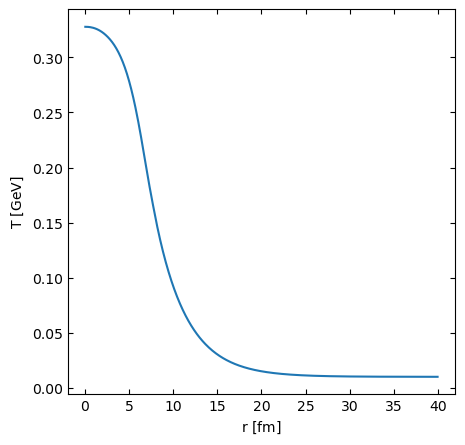

In [6]:
fields = Fluidum.initialize_fields(ent276, 0, 5; grid_params, initial_params);
#print(typeof(fields))
#eos = Heavy_Quark();
eos = FluiduMEoS();

plot_initial_field(fields; save=save_plots, path=directory*"initial_field_pce.png");

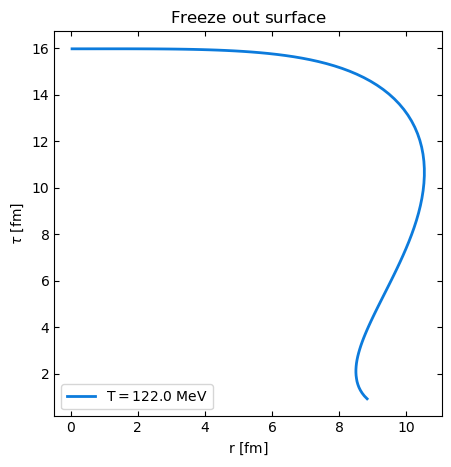

In [7]:
####################################zero diffusion
viscosity = QGPViscosity(2.0874/3.5,0.2); #or, ZeroViscosity();
bulk = SimpleBulkViscosity(0.017963,15.0); #or, ZeroBulkViscosity();

##########################no diffusion
diffusion = ZeroDiffusion();
params=Fluidum.FluidProperties(eos,viscosity,bulk,diffusion);
fo = freeze_out_routine(fields.discrete_field, Fluidum.matrxi1d_visc!_Tscale, params, fields.initial_field, tspan; Tfo = 0.1215);
plot_fo_surface(fo;save=save_plots);

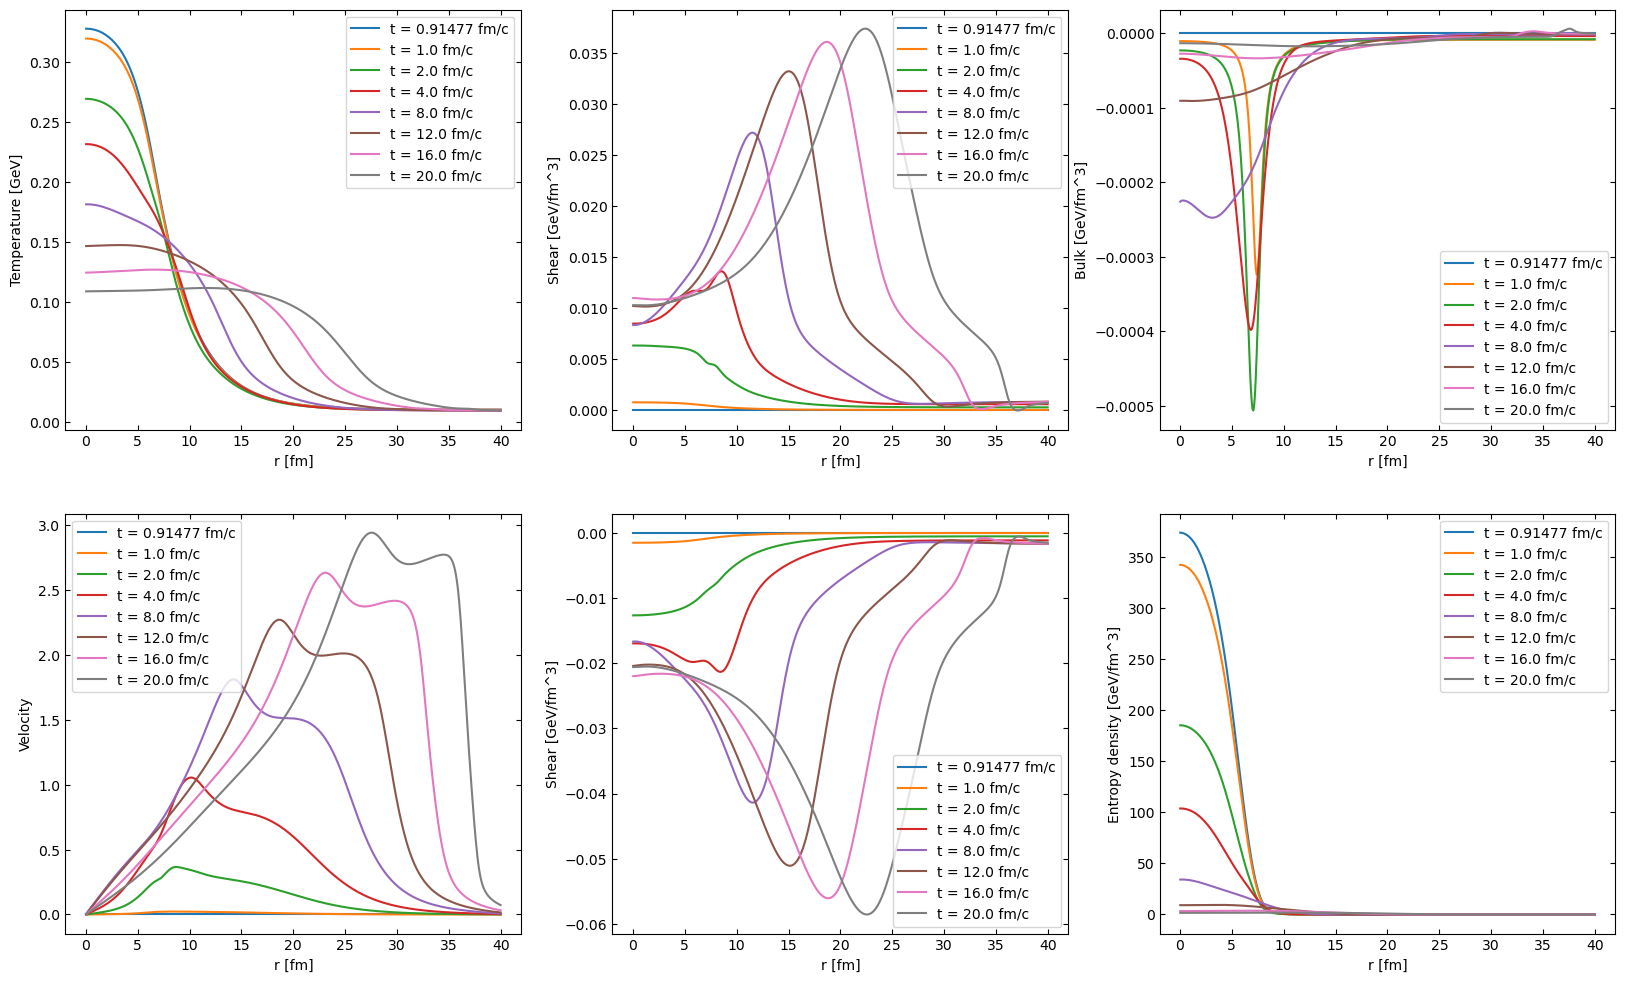

In [8]:
result_field = oneshoot(fields.discrete_field, Fluidum.matrxi1d_visc!, params, fields.initial_field, tspan; reltol = 1e-8);

times = [tspan[1], 1.0, 2.0, 4.0, 8.0, 12.0, 16.0, tspan[2]]
radius = zeros(gridpoints+2)
[radius[i]= disc.grid[i][1] for i in eachindex(disc.grid[1:end])] 

plot_result_fields(result_field, radius, times, params; save=save_plots);

Here begins my own plotting routine

In [9]:
include("Libs/data_lib.jl");

extraction_end_pion = 41; #number of data points to extract
filename_pion = "ExperimentalData/HEPData-ins1222333-v1-Table_1.csv"

data_pion = get_data(filename_pion, extraction_end_pion);
mult_pion_data = calculate_yield(data_pion; verbose=true);
mult_pion_data_excess = calculate_yield(data_pion; excess=true, verbose=true);
println("Pion data multiplicity (0.1 - 3.0 GeV/c): ", mult_pion_data[1], " +- ", mult_pion_data[2])
println("Pion data multiplicity (0.1 - 0.5 GeV/c): ", mult_pion_data_excess[1], " +- ", mult_pion_data_excess[2])

Yield: 682.1370916347523 + 0.46227961380718136 (stat) - 0.46227961380718136 (stat) + 11.575380312091593 (syst) - 11.575380312091593 (syst)
Yield: 682.1370916347523 ± 11.584607538060984 (total) + 11.584607538060984 (total) - 11.584607538060984 (total)

Yield: 397.03432248104536 + 0.3708293504388739 (stat) - 0.3708293504388739 (stat) + 10.904840995444424 (syst) - 10.904840995444424 (syst)
Yield: 397.03432248104536 ± 10.911144373670082 (total) + 10.911144373670082 (total) - 10.911144373670082 (total)

Pion data multiplicity (0.1 - 3.0 GeV/c): 682.1370916347523 +- 11.584607538060984
Pion data multiplicity (0.1 - 0.5 GeV/c): 397.03432248104536 +- 10.911144373670082


In [20]:
include("Libs/results_lib.jl");

#@show dic.pion
use_3d_kernel = false

results_pion_cuts = get_results_list(fo, dic_cuts, params, data_pion.pt; interpolate_3d=use_3d_kernel);

In [21]:
rescale_thermal::Bool = true;
rescale_total_refregion::Bool = false;

REFERENCE_MULT_TOTAL = 296.9204802282646
REFERENCE_MULT_THERMAL = 346.68494311992293

if rescale_thermal
    println("Rescaling to match all thermal spectra in (0.1 - 3.0 GeV/c) range, then match total spectra in (0.5 - 3.0 GeV/c) range.")
    rescaled_thermal_result_pion_cuts = rescale_result_list_thermal(results_pion_cuts; reference_mult = REFERENCE_MULT_THERMAL);
    if rescale_total_refregion
        println("Rescaling total result to match in (0.5 - 3.0 GeV/c) range.")
        rescaled_result_pion_cuts = rescale_result_list(rescaled_thermal_result_pion_cuts; reference_mult = REFERENCE_MULT_TOTAL); 
    else
        rescaled_result_pion_cuts = rescaled_thermal_result_pion_cuts;
    end
else
    if rescale_total_refregion
        println("Rescaling total result to match in (0.5 - 3.0 GeV/c) range.")
        rescaled_result_pion_cuts = rescale_result_list(results_pion_cuts; reference_mult = REFERENCE_MULT_TOTAL);
    else
        rescaled_result_pion_cuts = results_pion_cuts;
    end
end


Rescaling to match all thermal spectra in (0.1 - 3.0 GeV/c) range, then match total spectra in (0.5 - 3.0 GeV/c) range.
Reference thermal multiplicities (0.1 - 3.0 GeV/c): [346.68494311992293, 346.7010090876962, 337.87610311754173, 341.99449562922575, 343.3778384036376, 342.08458887959614, 344.16709644961014, 343.6734055496564, 340.21203179080294, 346.6435805997849, 343.72261001163395, 343.34065303247127, 344.1653118218618, 344.40904707850177, 345.2095218435451, 344.7364470829842, 340.14449818596654, 340.5407489849933, 347.6535759239107, 343.03299784569145, 347.8358813139734, 341.4348435414501, 343.9902348729902, 344.4367004406851, 345.11254050919473, 344.85511924612246, 341.82874598118093, 342.0863376171962, 344.72906170823865, 343.19526199592406, 343.98552379683093, 345.75545513410077, 341.31401491201524, 344.39431095591914, 342.4196402332139, 343.33808616671007, 339.9991517424193, 344.69340523766766, 341.8442597743324, 343.55151956736927, 344.04780443419514, 343.8101771157411, 344.3

ResultsList([[(400.94178173921557, 0.005964256008713753), (391.01798946842484, 0.003743158679499592), (379.38222395623774, 0.003861861023407659), (364.3190311266163, 0.004521702848959613), (348.017210305952, 0.0026154081577798305), (317.02314329884706, 0.0015711724856826148), (271.9088563173381, 0.003261288507132032), (229.98067428044442, 0.0023604467225366577), (193.10731053442694, 0.0018218383930559412), (161.2293810925379, 0.0014652499808097685)  …  (0.7509791652866286, 1.090643266352711e-5), (0.568265699253122, 7.640544544694223e-6), (0.4124097683769914, 5.852078886436782e-6), (0.31149346156838614, 4.603253095403871e-6), (0.22396652426355426, 3.075612226733943e-6), (0.17293727390728605, 2.468270943453624e-6), (0.12190789424786112, 1.8069539580627947e-6), (0.09489012300544496, 1.3734144718246509e-6), (0.07183059823808323, 1.0078165509055579e-6), (0.048771145344515016, 6.995888939143453e-7)], [(400.9452984198264, 0.0041991824421682145), (391.02114928778406, 0.0037629684935813756), (3

## Look at Reference

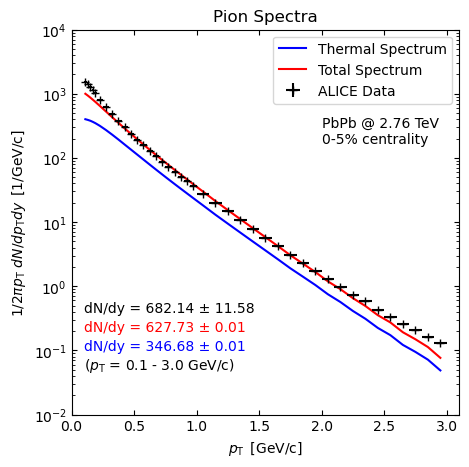

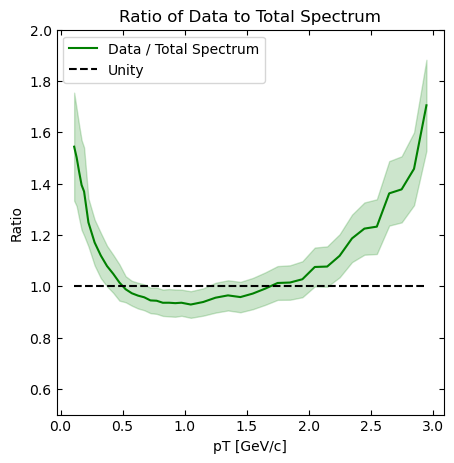

In [22]:
index = 1    # 1 : reference

test_reference = get_results_from_list_helper(results_pion_cuts, index)

plot_spectra(test_reference, data_pion, mult_pion_data; save=save_plots)
plot_ratio(test_reference, data_pion; save = save_plots)

In [23]:
excess, excess_err_exp, excess_err_mod = calculate_excess(test_reference, mult_pion_data_excess)

println("Pion excess multiplicity (0.1 - 0.5 GeV/c) for 0-5% centrality: ", excess, " +- ", excess_err_exp, " (exp) +- ", excess_err_mod, " (model)")

Pion excess multiplicity (0.1 - 0.5 GeV/c) for 0-5% centrality: 66.22433719143106 +- 10.911144373670082 (exp) +- 5.000002427358482 (model)


### All samples

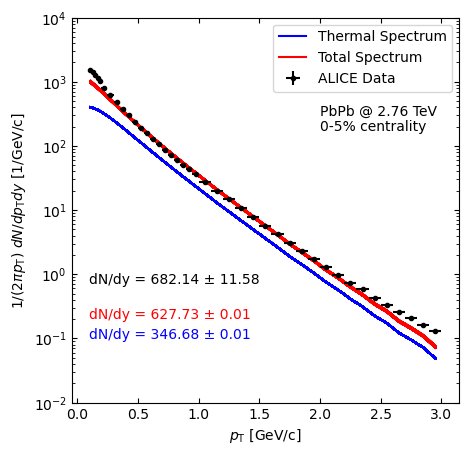

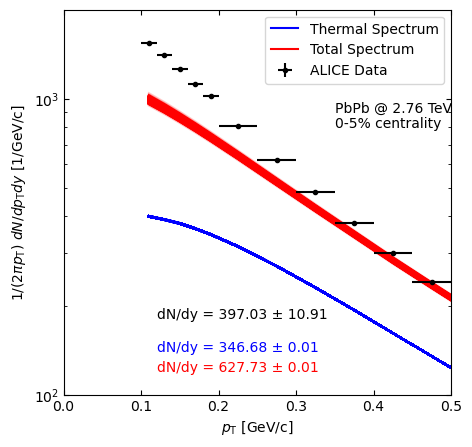

In [24]:
include("Libs/plotter_sampling.jl");

plot_sample_spectra(rescaled_result_pion_cuts, data_pion, mult_pion_data; save=save_plots)
plot_sample_spectra(rescaled_result_pion_cuts, data_pion, mult_pion_data_excess; excess=true, save=save_plots)

Mean Excess: 69.7018833266252 ± 3.1521401662278885


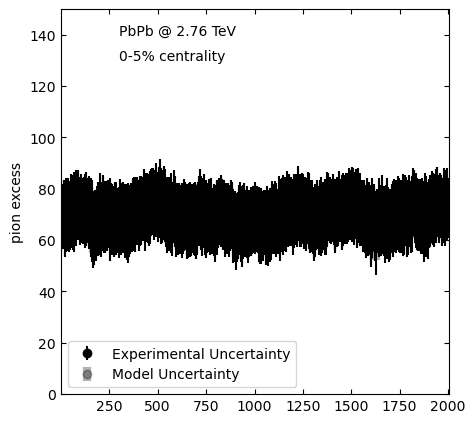

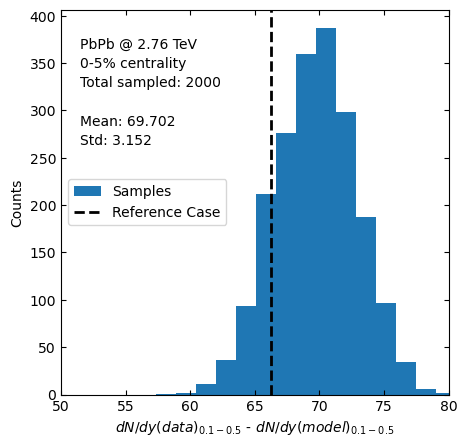

In [25]:
excess, excess_err_exp, excess_err_mod = calculate_excess_list(rescaled_result_pion_cuts, mult_pion_data_excess)

plot_excess(excess, excess_err_exp, excess_err_mod; save=save_plots)
plot_excess_hist(excess; save=save_plots)

Mean relative Excess: 0.10218163501354771 ± 0.004620977520330605


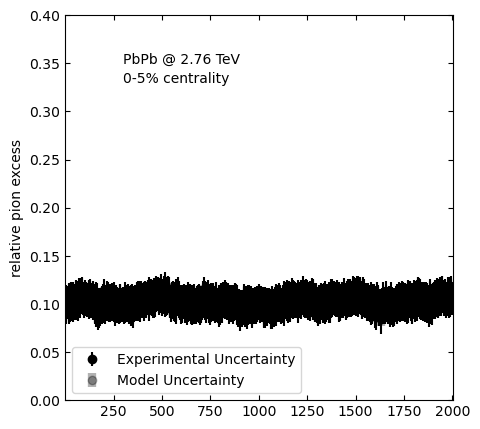

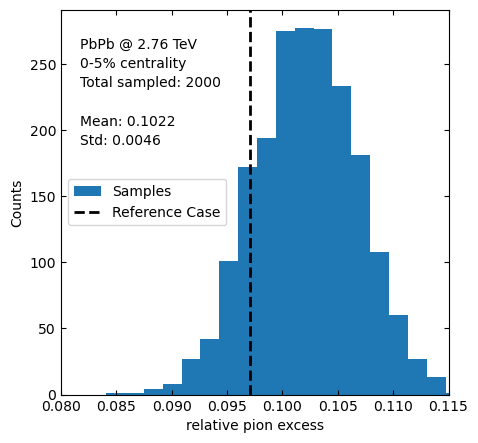

In [26]:
rel_excess, rel_excess_err_exp, rel_excess_err_mod = calculate_rel_excess_list(rescaled_result_pion_cuts, mult_pion_data, mult_pion_data_excess)

plot_rel_excess(rel_excess, rel_excess_err_exp, rel_excess_err_mod; save=save_plots)
plot_rel_excess_hist(rel_excess; save=save_plots)